# 03. 순위 표현은 정말 더 견고한가? — 깊이 변화 · 입력 ablation

**등급**: 🟢 Mac 로컬 (MPS/CPU) · **예상 시간**: Mac에서 약 20분, Colab T4에서 약 12분 (대부분 V2 추론) · **선행**: 노트북 01 · **다운로드**: 없음

**질문**
1. Geneformer 설명은 "순위 기반 표현은 기술적 아티팩트에 더 견고하다"고 한다. **시퀀싱 깊이가 달라지면**(참조는 깊게, 질의는 얕게) 임베딩 기반 세포 유형 분류가 PCA보다 덜 무너지는가?
2. 임베딩은 토큰열의 **무엇**에 의존하는가? (a) 검출 여부 집합, (b) 카운트에서 오는 순위, (c) 앞쪽 상위 유전자만, (d) 순서 자체.

**설계**
- 하위표본: 기증자당 ≈300개, 총 약 4,000세포 (노트북 01의 10.4k 하위표본에서 시드 0으로 뽑음). 속도 때문이며 희귀 세포 유형의 지표는 흔들린다. 그래서 기증자 단위 부트스트랩 구간으로 표시한다.
- 깊이 변화: 원시 카운트를 **이항 솎아내기**(각 카운트를 확률 p로 유지; p=0.5, 0.25)해 얕은 시퀀싱을 흉내낸다. n_counts도 솎아낸 행렬에서 다시 계산한다. 분류기는 **솎아내지 않은 다른 12명**의 임베딩으로 학습하고, held-out 기증자의 **솎아낸 세포**를 예측한다 (LODO). PCA의 HVG·표준화·축과 임베딩 평균 중심화도 **fold마다 그 12명의 솎아내지 않은 세포로만** 적합한다.
- 비교 대상: PCA(HVG) (fold별 12명의 깊은 세포로 적합한 HVG·표준화·PCA에 held-out 세포를 **투영**), Geneformer V1-10M, V2-104M. scVI는 새 데이터 변환 절차가 달라 제외했다.
- 이 솎아내기는 **이항 다운샘플링 시뮬레이션**이다. 실제 얕은 시퀀싱/다른 플랫폼의 차이(유전자별 검출 편향, 앰비언트 RNA 등)를 대표하지 않는다.

In [1]:
import hashlib
import io
import os
import pickle
import time
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
CACHE = (ROOT / ".cache") if ROOT is not None else Path("cache")
os.environ.setdefault("HF_HOME", str(CACHE / "hf"))
SC = CACHE / "singlecell"
for need in ["pbmc_sub.h5ad", "geneformer_embeddings.npz"]:
    assert (SC / need).exists(), f"{SC / need} 가 없다 — 노트북 01을 먼저 실행하라"

import torch
from huggingface_hub import hf_hub_download
from transformers import BertConfig, BertModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
import importlib.metadata as md

print("device:", DEVICE, {k: md.version(k) for k in ["numpy", "scipy", "scikit-learn", "scanpy", "anndata", "torch", "transformers"]})

W1110 12:18:13.306000 31884 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps {'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.5', 'anndata': '0.13.4', 'torch': '2.15.0', 'transformers': '5.22.1'}


## 0. 노트북 01의 구성요소 (독립 실행을 위해 복사)
허용 목록 Unpickler, `RankTokenizer`, 임베딩 추출. 동작은 노트북 01과 같다 (설명은 01 참고).

In [2]:
REV = "1f7fbae4e469a5f4f1af8c111a529cfe1b3829f5"
REPO = "ctheodoris/Geneformer"
FILES = {
    "v1": dict(model="Geneformer-V1-10M", tok="geneformer/gene_dictionaries_30m/token_dictionary_gc30M.pkl",
               med="geneformer/gene_dictionaries_30m/gene_median_dictionary_gc30M.pkl",
               map="geneformer/gene_dictionaries_30m/ensembl_mapping_dict_gc30M.pkl", max_len=2048, special=False),
    "v2": dict(model="Geneformer-V2-104M", tok="geneformer/token_dictionary_gc104M.pkl",
               med="geneformer/gene_median_dictionary_gc104M.pkl",
               map="geneformer/ensembl_mapping_dict_gc104M.pkl", max_len=4096, special=True),
}


def fetch(rel):
    return hf_hub_download(REPO, rel, revision=REV)


class SafeUnpickler(pickle.Unpickler):
    ALLOWED = {("numpy", "dtype"), ("numpy.core.multiarray", "scalar"), ("numpy._core.multiarray", "scalar")}

    def find_class(self, module, name):
        if (module, name) in self.ALLOWED:
            return super().find_class(module, name)
        raise pickle.UnpicklingError(f"blocked global: {module}.{name}")


def load_pkl(path):
    with open(path, "rb") as f:
        return SafeUnpickler(f).load()


class RankTokenizer:
    def __init__(self, version):
        cfg = FILES[version]
        self.tok = load_pkl(fetch(cfg["tok"]))
        self.med = load_pkl(fetch(cfg["med"]))
        mp = load_pkl(fetch(cfg["map"]))
        self.map = {k: v for k, v in mp.items() if v in self.tok}
        self.genes = [g for g in self.tok if g.startswith("ENS")]
        self.gidx = {g: i for i, g in enumerate(self.genes)}
        self.token_ids = np.array([self.tok[g] for g in self.genes])
        self.median = np.array([self.med[g] for g in self.genes])
        self.max_len, self.special = cfg["max_len"], cfg["special"]

    def collapse(self, counts, var_ids):
        mapped = pd.Series(np.asarray(var_ids)).str.upper().map(self.map)
        keep = np.where(mapped.notna().values)[0]
        cols = [self.gidx[mapped.iloc[i]] for i in keep]
        G = sp.csr_matrix((np.ones(len(keep)), (np.arange(len(keep)), cols)), shape=(len(keep), len(self.genes)))
        X = (counts[:, keep] @ G).tocsr()
        X.eliminate_zeros()
        return X

    def normalize_collapsed(self, Xc, n_counts, target_sum=10_000):
        return (sp.diags(target_sum / n_counts) @ Xc @ sp.diags(1.0 / self.median)).tocsr()

    def to_tokens(self, Xn, max_genes=None, shuffle_rng=None):
        L = self.max_len - (2 if self.special else 0)
        if max_genes is not None:
            L = min(L, max_genes)
        out = []
        for i in range(Xn.shape[0]):
            s, e = Xn.indptr[i], Xn.indptr[i + 1]
            v, ix = Xn.data[s:e], Xn.indices[s:e]
            t = self.token_ids[ix[np.argsort(-v, kind="stable")]][:L]
            if shuffle_rng is not None:                       # 유전자 토큰만 섞는다 (<cls>/<eos>는 그대로)
                t = shuffle_rng.permutation(t)
            if self.special:
                t = np.concatenate([[self.tok["<cls>"]], t, [self.tok["<eos>"]]])
            out.append(t.astype(np.int64))
        return out


@torch.no_grad()
def embed(model, token_lists, special, cls_id=None, eos_id=None, batch=32, layer=-2):
    n, H = len(token_lists), model.config.hidden_size
    order = np.argsort([len(t) for t in token_lists])
    mean_ = np.zeros((n, H), np.float32)
    cls_ = np.zeros((n, H), np.float32)
    for b in range(0, n, batch):
        bi = order[b:b + batch]
        ml = max(len(token_lists[i]) for i in bi)
        ids_ = torch.zeros(len(bi), ml, dtype=torch.long)
        for j, i in enumerate(bi):
            ids_[j, :len(token_lists[i])] = torch.from_numpy(token_lists[i])
        ids_ = ids_.to(DEVICE)
        att = ids_ != 0
        h = model(input_ids=ids_, attention_mask=att.long(), output_hidden_states=True).hidden_states[layer]
        gm = att.clone()
        if special:
            gm &= (ids_ != cls_id) & (ids_ != eos_id)
        m = gm.unsqueeze(-1).float()
        mean_[bi] = ((h * m).sum(1) / m.sum(1)).float().cpu().numpy()
        cls_[bi] = h[:, 0].float().cpu().numpy()
    return mean_, cls_


def load_model(version):
    path = Path(fetch(FILES[version]["model"] + "/config.json")).parent
    fetch(FILES[version]["model"] + "/model.safetensors")
    return BertModel.from_pretrained(path, add_pooling_layer=False).to(DEVICE).eval()


# 평가 함수 (노트북 02와 동일)
def prep(Z, center=True):
    Z = np.asarray(Z, dtype=np.float64)
    if center:
        Z = Z - Z.mean(0)
    return Z / np.linalg.norm(Z, axis=1, keepdims=True)


def knn_vote(Ztr, ytr, Zte, n_classes, k=15):
    S = Zte @ Ztr.T
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    votes = np.zeros((len(Zte), n_classes))
    rows = np.arange(len(Zte))
    for j in range(k):
        np.add.at(votes, (rows, ytr[idx[:, j]]), 1.0 + 1e-3 * S[rows, idx[:, j]])
    return votes.argmax(1)


def macro_f1_from_cm(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp, fn = cm.sum(-2) - tp, cm.sum(-1) - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.where(den > 0, den, 1), np.nan)
    return np.nanmean(f1, axis=-1)


def ci(x):
    return np.percentile(x[~np.isnan(x)], [2.5, 97.5])

## 1. 하위표본과 참조 임베딩
노트북 01이 저장한 10.4k 세포 중 기증자당 ≈300개를 뽑는다. 참조(솎아내지 않은) 임베딩은 01에서 저장한 것을 그대로 쓴다.

In [3]:
full = ad.read_h5ad(SC / "pbmc_sub.h5ad")
E = dict(np.load(SC / "geneformer_embeddings.npz"))
obs_full = full.obs
var_ids = np.array(full.var_names)
rng = np.random.default_rng(SEED)
sel = []
for d, g in obs_full.groupby("donor", observed=True).indices.items():
    sel += list(rng.choice(g, size=min(300, len(g)), replace=False))
sel = np.sort(np.array(sel))
obs = obs_full.iloc[sel]
counts0 = full.X[sel].tocsr() if sp.issparse(full.X) else sp.csr_matrix(full.X[sel])
counts0 = counts0.astype(np.float64)
labels, donors = obs.label.values, obs.donor.values
class_names, donor_names = sorted(obs.label.unique()), sorted(obs.donor.unique())
y = np.array([class_names.index(l) for l in labels])
print("하위표본:", counts0.shape, "| 세포 유형 분포:", dict(pd.Series(labels).value_counts()))

하위표본: (3900, 24505) | 세포 유형 분포: {'CD14 Monocyte': np.int64(802), 'CD4 T': np.int64(726), 'NK': np.int64(584), 'CD8 T': np.int64(580), 'B': np.int64(484), 'RBC': np.int64(215), 'PB': np.int64(158), 'CD16 Monocyte': np.int64(125), 'Granulocyte': np.int64(67), 'gd T': np.int64(55), 'DC': np.int64(43), 'Platelet': np.int64(34), 'pDC': np.int64(27)}


## 2. 이항 솎아내기로 얕은 시퀀싱 만들기
각 카운트 $c$를 $\mathrm{Binomial}(c, p)$로 바꾼다. 세포당 총 카운트와 검출 유전자 수가 어떻게 변하는지 먼저 본다.

In [4]:
def thin(counts, p, seed):
    out = counts.copy().tocsr()
    out.data = np.random.default_rng(seed).binomial(out.data.astype(np.int64), p).astype(np.float64)
    out.eliminate_zeros()
    return out


P_LIST = [0.5, 0.25]
thinned = {1.0: counts0}
for p in P_LIST:
    thinned[p] = thin(counts0, p, SEED + int(p * 100))
rows = []
for p, X in thinned.items():
    nc = np.asarray(X.sum(1)).ravel()
    rows.append({"p": p, "세포당 총 카운트 중앙값": np.median(nc), "최소": nc.min(), "검출 유전자 중앙값": np.median(np.diff(X.indptr)),
                 "카운트=1 항목 비율": float(np.mean(X.data == 1))})
print(pd.DataFrame(rows).set_index("p").round(2).to_string())
assert all(np.asarray(X.sum(1)).ravel().min() > 0 for X in thinned.values()), "빈 세포 발생"

      세포당 총 카운트 중앙값     최소  검출 유전자 중앙값  카운트=1 항목 비율
p                                                  
1.00         1483.5  505.0       894.0         0.77
0.50          741.0  261.0       513.0         0.83
0.25          372.0  143.0       286.0         0.88


## 3. PCA(HVG) baseline — fold마다 12명의 깊은 세포로 적합, held-out 세포는 투영
각 LODO fold에서 훈련 기증자 12명의 **솎아내지 않은** 세포로 HVG 2,000개(`seurat_v3`) · 로그 정규화의 유전자별 평균/표준편차 · PCA 50을 적합하고, 훈련 세포와 held-out 세포(원본·p=0.5·p=0.25)에 **같은 변환을 적용**한다 (재적합하지 않음). 얕은 질의를 "깊은 참조"에 올리는 상황이며 held-out 기증자의 원본 세포는 적합에 쓰이지 않는다.

In [5]:
def lognorm(X):
    X = sp.diags(1e4 / np.asarray(X.sum(1)).ravel()) @ X
    X = X.tocsr()
    X.data = np.log1p(X.data)
    return X


def fit_pca_projector(train_mask):
    a_ = ad.AnnData(X=counts0[train_mask].astype(np.float32), var=pd.DataFrame(index=var_ids))
    sc.pp.filter_genes(a_, min_cells=3)
    sc.pp.highly_variable_genes(a_, n_top_genes=2000, flavor="seurat_v3")
    hv = np.where(a_.var.highly_variable.values)[0]
    col = pd.Index(var_ids).get_indexer(a_.var_names.values)[hv]
    ref = lognorm(counts0[train_mask])[:, col].toarray()
    mu, sd = ref.mean(0), ref.std(0, ddof=1)
    sd[sd == 0] = 1
    pca = PCA(n_components=50, random_state=SEED).fit(np.clip((ref - mu) / sd, None, 10))
    return lambda X: pca.transform(np.clip((lognorm(X)[:, col].toarray() - mu) / sd, None, 10))


t0 = time.time()
PCA_FOLDS = []
for d in donor_names:
    te = donors == d
    proj = fit_pca_projector(~te)
    PCA_FOLDS.append((proj(counts0[~te]), {p: proj(thinned[p][te]) for p in thinned}))
print("fold별 PCA 적합·투영 완료: %.0f초 (fold %d개)" % (time.time() - t0, len(PCA_FOLDS)))
proj_all = fit_pca_projector(np.ones(counts0.shape[0], dtype=bool))      # 6절(깊이 R²)용: 전체 세포로 적합한 PCA (비지도, 기술적 질문이라 fold 분리하지 않는다)
Z_pca_all = proj_all(counts0)

fold별 PCA 적합·투영 완료: 7초 (fold 13개)


## 4. Geneformer 임베딩 — p=1.0은 01의 저장값, 솎아낸 입력은 새로 계산

In [6]:
t_v1, t_v2 = RankTokenizer("v1"), RankTokenizer("v2")
sel_in_full = sel          # 01 하위표본 안의 위치
Z = {}
Z["Geneformer V1-10M"] = {1.0: E["v1_mean_L-2"][sel_in_full]}
Z["Geneformer V2-104M"] = {1.0: E["v2_cls_L-2"][sel_in_full]}


def tokenize(t, X):
    Xc = t.collapse(X, var_ids)
    tk = t.to_tokens(t.normalize_collapsed(Xc, np.asarray(X.sum(1)).ravel()))
    assert min(len(x) for x in tk) > (2 if t.special else 0), "어휘 유전자가 하나도 없는 세포"
    return tk, Xc


# 재현 점검: 01의 저장 임베딩을 이 노트북의 토큰화로 다시 만들어 일치하는지 (V1, 30세포)
m1 = load_model("v1")
tk0, _ = tokenize(t_v1, counts0)
chk, _ = embed(m1, tk0[:30], False)
print("V1 재계산 vs 01 저장 임베딩 최대 절대차: %.2e" % np.abs(chk - Z["Geneformer V1-10M"][1.0][:30]).max())

t0 = time.time()
for p in P_LIST:
    tk, _ = tokenize(t_v1, thinned[p])
    Z["Geneformer V1-10M"][p] = embed(m1, tk, False)[0]
print("V1 솎아내기 임베딩: %.0f초" % (time.time() - t0))
del m1

m2 = load_model("v2")
cid, eid = t_v2.tok["<cls>"], t_v2.tok["<eos>"]
t0 = time.time()
tk0v2, _ = tokenize(t_v2, counts0)
chk2 = embed(m2, tk0v2[:30], True, cid, eid)[1]
print("V2 재계산 vs 01 저장(cls) 최대 절대차: %.2e" % np.abs(chk2 - Z["Geneformer V2-104M"][1.0][:30]).max())
for p in P_LIST:
    tk, _ = tokenize(t_v2, thinned[p])
    Z["Geneformer V2-104M"][p] = embed(m2, tk, True, cid, eid)[1]
print("V2 솎아내기 임베딩: %.0f초" % (time.time() - t0))
del m2
if DEVICE.type == "mps":
    torch.mps.empty_cache()

V1 재계산 vs 01 저장 임베딩 최대 절대차: 5.96e-08


V1 솎아내기 임베딩: 17초


V2 재계산 vs 01 저장(cls) 최대 절대차: 0.00e+00


V2 솎아내기 임베딩: 195초


## 5. 깊이 변화 평가
- **분류**: 참조(p=1) 임베딩으로 학습한 kNN(k=15)이 held-out 기증자의 솎아낸 세포를 분류한 macro-F1과 정확도 (LODO). `p=1.0`은 학습·평가 모두 솎아내지 않은 경우(상한 기준). 임베딩 중심화 평균도 fold별 훈련 기증자의 것이다.
- **자기 유사도**: held-out 세포의 참조(p=1) 임베딩과 솎아낸 임베딩의 코사인 유사도 평균. 높다고 분류가 보존된다는 뜻은 아니다. 모든 세포가 비슷해 보이는 임베딩(anisotropy)에서도 높을 수 있다.
- 부트스트랩 구간은 이미 계산된 fold별 예측을 기증자 단위로 재표본한 **조건부** 구간이다 (노트북 02와 동일).

In [7]:
B = 1000
boot = np.random.default_rng(SEED).integers(0, len(donor_names), size=(B, len(donor_names)))
C = len(class_names)
PS = [1.0] + P_LIST


def run_method(get_fold):
    """get_fold(i, te) -> (훈련 임베딩 [p=1], {p: held-out 임베딩}). 중심화는 훈련 기증자 평균."""
    cms = {p: np.zeros((len(donor_names), C, C)) for p in PS}
    sims = {p: [] for p in P_LIST}
    for i, d in enumerate(donor_names):
        te = donors == d
        Ztr, Zte = get_fold(i, te)
        mu_ = Ztr.mean(0)
        R_ = prep(Ztr - mu_, False)
        T_ = {p: prep(Zte[p] - mu_, False) for p in PS}
        for p in PS:
            pred = knn_vote(R_, y[~te], T_[p], C)
            np.add.at(cms[p][i], (y[te], pred), 1)
        for p in P_LIST:
            sims[p].append((T_[1.0] * T_[p]).sum(1))
    return cms, {p: float(np.concatenate(v).mean()) for p, v in sims.items()}


METHODS = {"PCA(HVG,50)": lambda i, te: PCA_FOLDS[i]}
for name, byp in Z.items():
    METHODS[name] = (lambda byp_: (lambda i, te: (byp_[1.0][~te], {p: byp_[p][te] for p in PS})))(byp)

res, cms_store = [], {}
for name, getter in METHODS.items():
    cms_p, sim_p = run_method(getter)
    for p in PS:
        cms = cms_p[p]
        cms_store[(name, p)] = cms
        f1 = macro_f1_from_cm(cms.sum(0))
        fb = macro_f1_from_cm(cms[boot].sum(1))
        res.append(dict(방법=name, p=p, macroF1=f1, lo=ci(fb)[0], hi=ci(fb)[1], 정확도=np.trace(cms.sum(0)) / cms.sum(), 자기유사도=1.0 if p == 1.0 else sim_p[p]))
R = pd.DataFrame(res)
R["macro-F1 [95% CI]"] = R.apply(lambda r: f"{r.macroF1:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)
print(R.pivot(index="방법", columns="p", values="macro-F1 [95% CI]").to_string())
print()
print(R.pivot(index="방법", columns="p", values="정확도").round(3).to_string())
print()
print("자기 유사도 (fold 훈련 평균 중심화 후 코사인, held-out 세포):")
print(R.pivot(index="방법", columns="p", values="자기유사도").round(3).to_string())

# 짝지은 하락폭: p=1 대비 macro-F1 감소 (기증자 부트스트랩)
rows = []
for name in METHODS:
    for p in P_LIST:
        d = macro_f1_from_cm(cms_store[(name, p)][boot].sum(1)) - macro_f1_from_cm(cms_store[(name, 1.0)][boot].sum(1))
        dd = macro_f1_from_cm(cms_store[(name, p)].sum(0)) - macro_f1_from_cm(cms_store[(name, 1.0)].sum(0))
        rows.append({"방법": name, "p": p, "Δ macro-F1 (p vs 1.0)": f"{dd:+.3f} [{ci(d)[0]:+.3f}, {ci(d)[1]:+.3f}]"})
print("\n솎아내기로 인한 macro-F1 변화:")
print(pd.DataFrame(rows).pivot(index="방법", columns="p", values="Δ macro-F1 (p vs 1.0)").to_string())

p                                   0.25                  0.50                  1.00
방법                                                                                  
Geneformer V1-10M   0.191 [0.155, 0.222]  0.357 [0.294, 0.398]  0.512 [0.447, 0.545]
Geneformer V2-104M  0.531 [0.470, 0.589]  0.742 [0.662, 0.797]  0.799 [0.735, 0.842]
PCA(HVG,50)         0.775 [0.703, 0.811]  0.828 [0.762, 0.867]  0.856 [0.789, 0.894]

p                    0.25   0.50   1.00
방법                                     
Geneformer V1-10M   0.337  0.585  0.712
Geneformer V2-104M  0.595  0.807  0.843
PCA(HVG,50)         0.831  0.871  0.891

자기 유사도 (fold 훈련 평균 중심화 후 코사인, held-out 세포):
p                    0.25   0.50  1.00
방법                                    
Geneformer V1-10M   0.222  0.520   1.0
Geneformer V2-104M  0.377  0.672   1.0
PCA(HVG,50)         0.767  0.912   1.0

솎아내기로 인한 macro-F1 변화:
p                                      0.25                     0.50
방법                                        

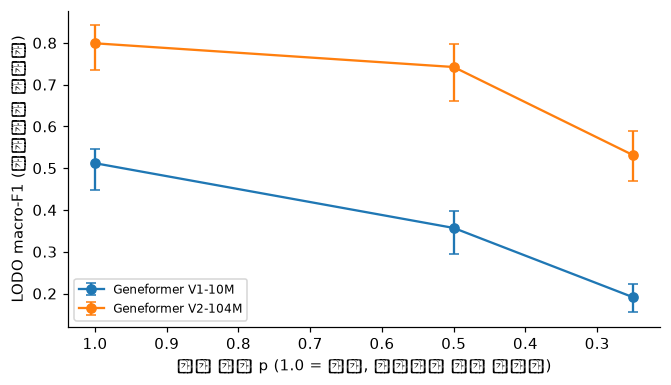

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for name in Z:
    s = R[R.방법 == name].sort_values("p", ascending=False)
    ax.errorbar(s.p, s.macroF1, yerr=[s.macroF1 - s.lo, s.hi - s.macroF1], marker="o", capsize=3, label=name)
ax.set_xlabel("유지 확률 p (1.0 = 원본, 작을수록 얕은 시퀀싱)")
ax.set_ylabel("LODO macro-F1 (테스트만 솎아냄)")
ax.invert_xaxis()
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. 임베딩이 깊이(총 카운트)를 담고 있는가
임베딩에서 `log(총 카운트)`를 릿지 회귀로 예측한 $R^2$. 값이 크면 임베딩 축 일부가 기술적 깊이와 연결되어 있다는 뜻이다 (깊이가 세포 유형·기증자와 상관되어 있으면 생물학·기증자 신호가 섞여 있을 수 있다).
- **무작위 5-fold**: 세포를 섞어 나눈다. 같은 기증자의 세포가 훈련·테스트에 모두 들어가 기증자별 깊이 차이를 이용할 수 있다.
- **기증자 단위(LODO)**: 새 기증자의 깊이를 예측하므로 더 보수적이다.
PCA는 이 절에서만 전체 세포로 적합한 것을 쓴다 (기술적 질문이라 비지도 적합을 fold로 나누지 않음).

In [9]:
logn = np.log(np.asarray(thinned[1.0].sum(1)).ravel())
rows = []
emb_depth = {"PCA(HVG,50)": Z_pca_all, "Geneformer V1-10M": Z["Geneformer V1-10M"][1.0], "Geneformer V2-104M": Z["Geneformer V2-104M"][1.0]}


def r2_of(pred):
    return 1 - ((logn - pred) ** 2).sum() / ((logn - logn.mean()) ** 2).sum()


for name, Zd in emb_depth.items():
    Xp = prep(Zd - Zd.mean(0), False)
    rid = RidgeCV(alphas=np.logspace(-3, 3, 13))
    r_rand = r2_of(cross_val_predict(rid, Xp, logn, cv=KFold(5, shuffle=True, random_state=SEED)))
    r_lodo = r2_of(cross_val_predict(rid, Xp, logn, cv=GroupKFold(n_splits=len(donor_names)), groups=donors))
    rows.append({"임베딩": name, "무작위 5-fold R²": r_rand, "기증자 단위 LODO R²": r_lodo})
print(pd.DataFrame(rows).set_index("임베딩").round(3).to_string())
eta = 1 - sum(((logn[labels == l] - logn[labels == l].mean()) ** 2).sum() for l in class_names) / ((logn - logn.mean()) ** 2).sum()
eta_d = 1 - sum(((logn[donors == l] - logn[donors == l].mean()) ** 2).sum() for l in donor_names) / ((logn - logn.mean()) ** 2).sum()
print("log(총 카운트) 분산 중 세포 유형이 설명하는 비율 η²: %.3f | 기증자가 설명하는 비율 η²: %.3f" % (eta, eta_d))

                    무작위 5-fold R²  기증자 단위 LODO R²
임베딩                                              
PCA(HVG,50)                 0.626           0.585
Geneformer V1-10M           0.903           0.890
Geneformer V2-104M          0.932           0.921
log(총 카운트) 분산 중 세포 유형이 설명하는 비율 η²: 0.057 | 기증자가 설명하는 비율 η²: 0.108


## 7. 입력 ablation — 임베딩은 토큰열의 무엇에 의존하는가
같은 하위표본에서 Geneformer V1 입력을 네 가지로 바꿔 **새 임베딩을 계산**하고, 학습·평가(LODO)를 모두 그 입력으로 한다. (`<cls>`/`<eos>`가 있는 V2에서 순서를 섞을 때는 유전자 토큰만 섞도록 구현했다.)
- **전체 순위**: 원래 방식.
- **검출 집합만(count-blind)**: 카운트를 모두 1로 바꿔 검출된 유전자를 코퍼스 중앙값의 역순으로만 정렬. 세포마다 **검출된 유전자 집합**만 다르고 카운트 정보는 없다. 형식은 유효한 순위열이지만 카운트가 모두 1인 세포는 사전학습 분포와 다를 수 있다(분포 이동 가능성).
- **상위 256개만**: 순위 앞쪽 256개 유전자로 절단.
- **순서 무작위화**: 같은 유전자 집합을 세포마다 무작위로 섞음. 사전학습에서 본 적 없는 입력이라 성능 하락이 곧 "순서에 정보가 있다"는 증거는 아니다 (분포 밖).
V2는 시간 때문에 "검출 집합만"만 수행한다.

In [10]:
def tokens_variant(t, X, kind, seed=SEED):
    Xc = t.collapse(X, var_ids)
    if kind == "full":
        return t.to_tokens(t.normalize_collapsed(Xc, np.asarray(X.sum(1)).ravel()))
    if kind == "top256":
        return t.to_tokens(t.normalize_collapsed(Xc, np.asarray(X.sum(1)).ravel()), max_genes=256)
    if kind == "detect_only":
        Xb = Xc.copy()
        Xb.data[:] = 1.0
        return t.to_tokens(t.normalize_collapsed(Xb, np.ones(Xb.shape[0]) * 1e4))
    if kind == "shuffle":
        return t.to_tokens(t.normalize_collapsed(Xc, np.asarray(X.sum(1)).ravel()), shuffle_rng=np.random.default_rng(seed))


def lodo_same(Zx):
    """학습·평가 모두 같은 입력 변형의 임베딩. 중심화는 fold별 훈련 기증자 평균."""
    cms = np.zeros((len(donor_names), C, C))
    for i, d in enumerate(donor_names):
        te = donors == d
        mu_ = Zx[~te].mean(0)
        pred = knn_vote(prep(Zx[~te] - mu_, False), y[~te], prep(Zx[te] - mu_, False), C)
        np.add.at(cms[i], (y[te], pred), 1)
    return cms


abl = {}
m1 = load_model("v1")
t0 = time.time()
for kind in ["full", "detect_only", "top256", "shuffle"]:
    tk = tokens_variant(t_v1, counts0, kind)
    assert min(len(x) for x in tk) > 0
    L = np.array([len(x) for x in tk])
    abl[("V1", kind)] = (embed(m1, tk, False)[0], L.mean())
print("V1 ablation 임베딩: %.0f초" % (time.time() - t0))
del m1
m2 = load_model("v2")
t0 = time.time()
for kind in ["detect_only"]:
    tk = tokens_variant(t_v2, counts0, kind)
    abl[("V2", kind)] = (embed(m2, tk, True, cid, eid)[1], np.mean([len(x) for x in tk]))
abl[("V2", "full")] = (Z["Geneformer V2-104M"][1.0], np.mean([len(x) for x in tk0v2]))
print("V2 ablation 임베딩: %.0f초" % (time.time() - t0))
del m2
if DEVICE.type == "mps":
    torch.mps.empty_cache()

cms_abl = {k: lodo_same(Zx) for k, (Zx, L) in abl.items()}
rows = []
for (mdl, kind), (Zx, L) in abl.items():
    cms = cms_abl[(mdl, kind)]
    f1 = macro_f1_from_cm(cms.sum(0))
    fb = macro_f1_from_cm(cms[boot].sum(1))
    if kind == "full":
        delta = "—"
    else:
        d_ = fb - macro_f1_from_cm(cms_abl[(mdl, "full")][boot].sum(1))      # 같은 재표본으로 짝지은 차이
        delta = f"{f1 - macro_f1_from_cm(cms_abl[(mdl, 'full')].sum(0)):+.3f} [{ci(d_)[0]:+.3f}, {ci(d_)[1]:+.3f}]"
    rows.append({"모델": mdl, "입력": kind, "평균 토큰 수": round(L), "macro-F1 [95% CI]": f"{f1:.3f} [{ci(fb)[0]:.3f}, {ci(fb)[1]:.3f}]",
                 "Δ vs 전체 순위 [95% CI]": delta, "정확도": round(np.trace(cms.sum(0)) / cms.sum(), 3)})
print(pd.DataFrame(rows).set_index(["모델", "입력"]).to_string())

V1 ablation 임베딩: 85초


V2 ablation 임베딩: 262초


                평균 토큰 수     macro-F1 [95% CI]      Δ vs 전체 순위 [95% CI]    정확도
모델 입력                                                                        
V1 full             910  0.512 [0.447, 0.545]                        —  0.712
   detect_only      910  0.459 [0.397, 0.490]  -0.053 [-0.072, -0.031]  0.698
   top256           253  0.463 [0.395, 0.500]  -0.049 [-0.082, -0.016]  0.628
   shuffle          910  0.300 [0.243, 0.326]  -0.212 [-0.241, -0.184]  0.516
V2 detect_only      911  0.731 [0.660, 0.774]  -0.068 [-0.089, -0.044]  0.813
   full             911  0.799 [0.735, 0.842]                        —  0.843


## 8. 해석과 한계
아래는 이 실행(seed 0, 13명×300세포 = 3,900세포)에서 읽은 내용이다. **표를 직접 확인한다.**

**깊이 변화**
- 총 카운트 중앙값을 1,483.5 → 741 (p=0.5) → 372 (p=0.25)로 줄이면 카운트=1 항목의 비율이 0.77 → 0.83 → 0.88로 늘고 검출 유전자 수 중앙값은 894 → 513 → 286으로 준다.
- 깊은 참조(fold별 훈련 기증자 12명)로 학습하고 얕은 세포를 분류했을 때 macro-F1: **PCA 0.856 → 0.828 → 0.775**, V1 0.512 → 0.357 → 0.191, V2 0.799 → 0.742 → 0.531. p=1 대비 하락폭은 PCA −0.028 [−0.043, −0.009] / −0.081 [−0.118, −0.049], V1 −0.155 [−0.186, −0.117] / −0.321 [−0.345, −0.276], V2 −0.057 [−0.096, −0.030] / −0.268 [−0.303, −0.229]. **"순위 기반 표현이 깊이 차이에 더 견고하다"는 설명은 이 시뮬레이션에서 지지되지 않았다.** 로그 정규화 후 깊은 참조에서 적합한 PCA 투영이 훨씬 덜 무너졌다. (PCA도 p=0.25에서는 0.08 하락하므로 "깊이에 무관"한 것은 아니다.)
- 같은 세포의 참조 임베딩과 솎아낸 임베딩의 코사인 유사도(자기 유사도)는 PCA 0.91/0.77, V1 0.52/0.22, V2 0.67/0.38이다. 순위는 "덜 바뀌는" 것이 아니라 **검출 집합이 바뀌면 토큰열이 크게 바뀐다.** 얕은 시퀀싱에서는 낮은 발현 유전자가 사라지고 남은 유전자의 순위가 재배열된다.
- V2가 모든 조건에서 V1보다 높다. 그러나 두 모델은 크기(104M 대 10M), 사전학습 코퍼스(약 1억 대 3천만 세포), 입력 길이, 어휘, `<cls>` 사용이 함께 다르므로 **어느 요인 때문인지 이 실험으로는 분리할 수 없다.**

**깊이가 임베딩에 얼마나 들어 있는가**
- 임베딩에서 `log(총 카운트)`를 예측한 R²: 무작위 5-fold PCA 0.63 / V1 0.90 / V2 0.93, 기증자 단위(LODO) 0.59 / 0.89 / 0.92. 기증자를 통째로 빼도 거의 같으므로 기증자별 깊이 차이만으로 설명되지는 않는다. 세포 유형이 설명하는 `log(총 카운트)` 분산은 5.7%, 기증자는 10.8%이므로 나머지는 세포 상태 등 다른 요인이거나 기술적 깊이 자체일 수 있다. 이 R²만으로 "깊이를 인코딩한다"고 단정할 수 없고, Geneformer 임베딩에는 깊이와 연결된 방향이 PCA보다 **더 강하게** 있다는 정도로만 읽는다 (차원이 다르므로(50 대 256/768) 순위 비교는 조심한다). 이것이 얕은 질의에서 임베딩이 크게 움직이는 한 이유라는 것은 **가설**이다(직접 시험하지 않음; 예: 깊이를 회귀로 제거한 뒤 재평가).

**입력 ablation**
- 전체 순위 대비 짝지은 차이: 검출 집합만 → **V1 −0.053 [−0.072, −0.031], V2 −0.068 [−0.089, −0.044]**, 상위 256개만(V1) −0.049 [−0.082, −0.016], 순서 무작위화(V1) −0.212 [−0.241, −0.184]. 카운트 정보를 전부 지워도 macro-F1이 0.51/0.80에서 5~7점(상대적으로 약 9~10%)만 줄어든다. 0은 아니므로 **카운트에서 오는 순위 정보의 기여가 있기는 하지만 이 데이터에서 관찰된 크기는 작다.** 노트북 02의 무작위 초기화 결과와 함께 보면 이 데이터에서 임베딩의 세포 유형 신호 상당 부분이 **검출된 유전자 집합**과 연결되어 있다. 다만 "검출 집합만" 입력은 형식은 유효한 순위열이지만 카운트가 모두 1인 세포는 사전학습 분포와 다를 수 있어(분포 이동 가능성) 위 차이를 "카운트 정보의 고유 기여"로 확정하지는 않는다. 얕은 데이터(카운트=1이 77%)라는 조건과 결합된 결과이며 깊은 데이터에도 같다고 말할 수 없다.
- 순서를 무작위화하면 크게 떨어지지만 이는 사전학습에서 본 적 없는 **분포 밖 입력**이므로 "순서에 생물학 정보가 있다"는 증거로 해석하면 안 된다.

**한계**
- 이항 솎아내기는 **시뮬레이션**이다. 실제 얕은 시퀀싱·다른 플랫폼은 유전자별 검출 편향, 앰비언트 RNA 등이 다르다. 솎아낸 p=0.25 세포는 총 카운트가 최소 143까지 내려가 사전학습 분포와 멀 수 있다.
- PCA는 "깊은 참조에서 적합 후 투영"이라는 한 가지 방식만 봤다. 얕은 세포를 함께 섞어 학습하는 깊이 증강, Geneformer 임베딩 위의 지도 분류기(probe) 등은 시험하지 않았다. 그래서 결론은 **zero-shot 임베딩 + 깊은 참조 kNN**에 한정된다.
- 하위표본 3,900세포라 작은 유형(pDC 등)은 지표가 흔들린다. 시드 하나, 단일 데이터셋이다. 부트스트랩 구간은 예측을 기증자 단위로 재표본한 조건부 구간이다.